# Fairness Analysis — Equal Error Rate (EER)

**Equal Error Rate** is the operating point where the model’s false-approval rate (FPR) equals its false-denial rate (FNR). Lower EER means better separation of approvals vs denials.

For each protected group we find that threshold separately, then compare EER across groups.

- Lower EER is better for that group  
- **EER gap (Black − White):** closer to 0 means the two groups face a similar error tradeoff  
- This follows the team discussion to use EER for group comparison


In [1]:
import sys
sys.path.append('../scripts')
import os
os.environ.setdefault('KERAS_BACKEND', 'torch')

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from fairness_eval import _approval_probability, HMDA_LABELS

X_test = pd.read_csv('../data/features/X_test_prep.csv', index_col='row_id')
y_test = pd.read_csv('../data/features/y_test.csv', index_col='row_id')['is_approved']
protected = pd.read_csv('../data/features/protected_test.csv', index_col='row_id')

MODELS = {
  'Logistic Regression': joblib.load('../data/models/logistic_regression_model.joblib'),
  'Decision Tree': joblib.load('../data/models/decision_tree_model.joblib'),
  'RF Balanced': joblib.load('../data/models/random_forest_balanced.joblib'),
  'RF Imbalanced': joblib.load('../data/models/random_forest_classifier_imbalanced.joblib'),
  'RF Protected*': joblib.load('../data/models/random_forest_balanced_protected.joblib'),
  'XGBoost': joblib.load('../data/models/xgboost_model.joblib'),
}
import keras
MODELS['Neural Network'] = keras.models.load_model('../data/models/neural_network_model.keras')
SCORES = {name: _approval_probability(model, X_test) for name, model in MODELS.items()}
print('Loaded', len(MODELS), 'models')


Loaded 7 models


In [2]:
def eer_for_scores(y_true, scores, n_thresholds=1001):
  """EER = rate where FPR ~= FNR (approval is the positive class)."""
  y = np.asarray(y_true).astype(bool)
  s = np.asarray(scores, dtype=float)
  if y.sum() == 0 or (~y).sum() == 0:
    return np.nan, np.nan
  best = None
  for thr in np.linspace(0, 1, n_thresholds):
    pred = s >= thr
    fpr = pred[~y].mean()   # approved though denied
    fnr = (~pred)[y].mean() # denied though approved
    diff = abs(fpr - fnr)
    eer = 0.5 * (fpr + fnr)
    if best is None or diff < best[0]:
      best = (diff, float(eer), float(thr))
  return best[1], best[2]


def group_eer_table(scores, group_col_name, group_values):
  labels_map = HMDA_LABELS.get(group_col_name, {})
  labels = group_values.map(lambda x: labels_map.get(x, x)) if labels_map else group_values
  y = y_test.to_numpy()
  s = np.asarray(scores)
  records = []
  eer, thr = eer_for_scores(y, s)
  records.append({group_col_name: 'overall', 'n': len(y), 'eer': eer, 'threshold': thr})
  for key in labels.value_counts().index:
    mask = (labels == key).to_numpy()
    eer_g, thr_g = eer_for_scores(y[mask], s[mask])
    records.append({group_col_name: key, 'n': int(mask.sum()), 'eer': eer_g, 'threshold': thr_g})
  return pd.DataFrame(records)


def eer_compare(eer_tables, group_col, group_a, group_b, title):
  def val(table, name):
    return float(table.loc[table[group_col] == name, 'eer'].iloc[0])
  labels = list(eer_tables.keys())
  a_vals = [val(eer_tables[name], group_a) for name in labels]
  b_vals = [val(eer_tables[name], group_b) for name in labels]
  x = np.arange(len(labels))
  width = 0.38
  fig, ax = plt.subplots(figsize=(max(10, 1.5 * len(labels)), 5.5))
  bars_a = ax.bar(x - width/2, a_vals, width, label=group_a, color='#4C78A8')
  bars_b = ax.bar(x + width/2, b_vals, width, label=group_b, color='#F58518')
  for bars in (bars_a, bars_b):
    for bar in bars:
      h = bar.get_height()
      if np.isnan(h):
        continue
      ax.text(bar.get_x()+bar.get_width()/2, h+0.01, f'{h:.0%}',
              ha='center', va='bottom', fontsize=9, fontweight='bold')
  for i, (va, vb) in enumerate(zip(a_vals, b_vals)):
    if np.isnan(va) or np.isnan(vb):
      continue
    ax.text(i, max(va, vb)+0.06, f'gap {vb-va:+.0%}', ha='center', fontsize=9, color='#B35C00')
  ax.set_ylim(0, max(0.55, np.nanmax(a_vals + b_vals) + 0.12))
  ax.set_ylabel('Equal Error Rate (lower is better)')
  ax.set_xticks(x)
  ax.set_xticklabels(labels, fontsize=8, rotation=20, ha='right')
  ax.set_title(title, fontsize=14, fontweight='bold')
  ax.legend(loc='upper right')
  plt.tight_layout()
  plt.show()


## Race — Black vs White EER


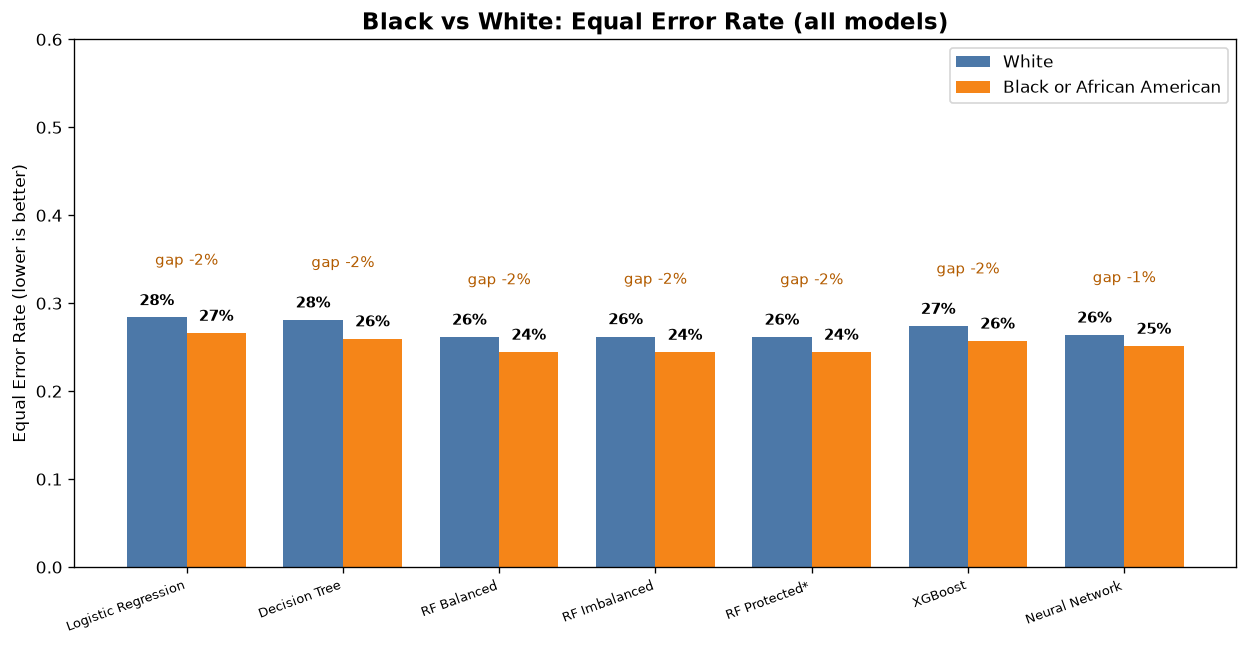

In [3]:
eer_race = {name: group_eer_table(SCORES[name], 'applicant_race_1', protected['applicant_race_1'])
              for name in MODELS}
eer_compare(
  eer_race, 'applicant_race_1',
  'White', 'Black or African American',
  'Black vs White: Equal Error Rate (all models)',
)


## Sex — Female vs Male EER


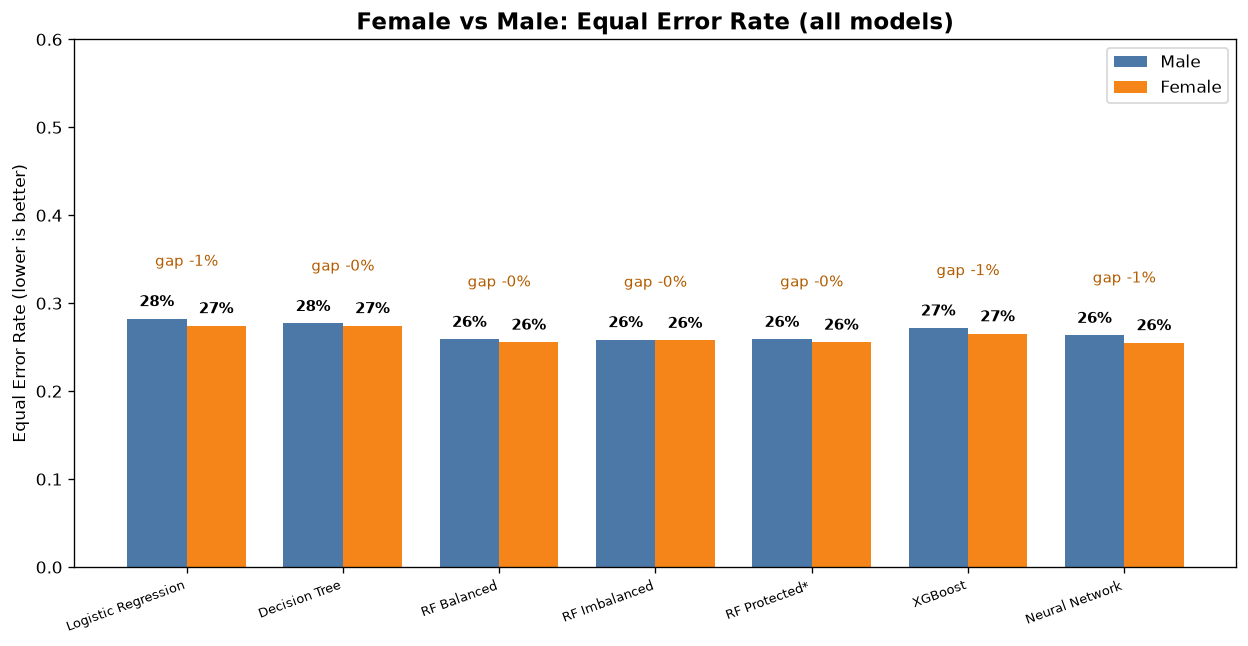

In [4]:
eer_sex = {name: group_eer_table(SCORES[name], 'applicant_sex', protected['applicant_sex'])
              for name in MODELS}
eer_compare(
  eer_sex, 'applicant_sex',
  'Male', 'Female',
  'Female vs Male: Equal Error Rate (all models)',
)


## Ethnicity — Hispanic vs Not Hispanic EER


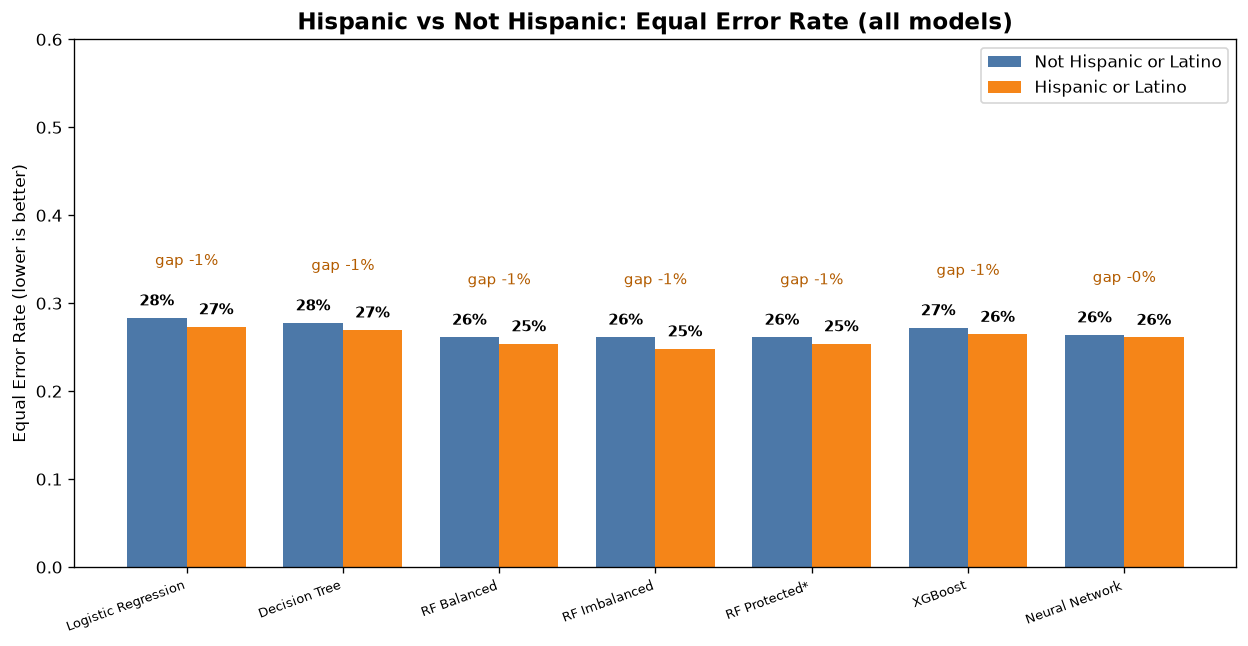

In [5]:
eer_eth = {name: group_eer_table(SCORES[name], 'applicant_ethnicity', protected['applicant_ethnicity'])
              for name in MODELS}
eer_compare(
  eer_eth, 'applicant_ethnicity',
  'Not Hispanic or Latino', 'Hispanic or Latino',
  'Hispanic vs Not Hispanic: Equal Error Rate (all models)',
)


## Model scorecard — EER + performance

Lower overall EER is better. EER gap closer to 0 is fairer across Black vs White.


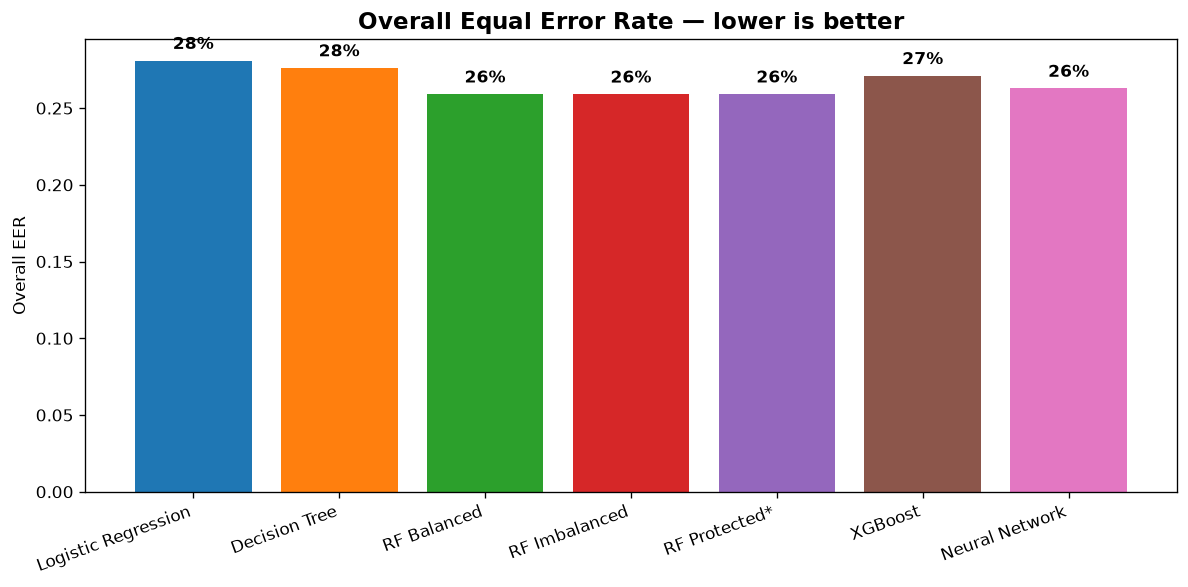

In [6]:
# Overall EER per model
rows = []
for name in MODELS:
  t = eer_race[name]
  w = t.loc[t['applicant_race_1'] == 'White'].iloc[0]
  b = t.loc[t['applicant_race_1'] == 'Black or African American'].iloc[0]
  o = t.loc[t['applicant_race_1'] == 'overall'].iloc[0]
  rows.append({
    'model': name,
    'eer_overall': o['eer'],
    'eer_white': w['eer'],
    'eer_black': b['eer'],
    'eer_gap_bw': b['eer'] - w['eer'],
  })
eer_scorecard = pd.DataFrame(rows)

x = np.arange(len(eer_scorecard))
fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(x, eer_scorecard['eer_overall'], color=plt.cm.tab10.colors[:len(eer_scorecard)])
for bar, v in zip(bars, eer_scorecard['eer_overall']):
  ax.text(bar.get_x()+bar.get_width()/2, v+0.005, f'{v:.0%}', ha='center', va='bottom', fontsize=10, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(eer_scorecard['model'], rotation=20, ha='right')
ax.set_ylabel('Overall EER')
ax.set_title('Overall Equal Error Rate — lower is better', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


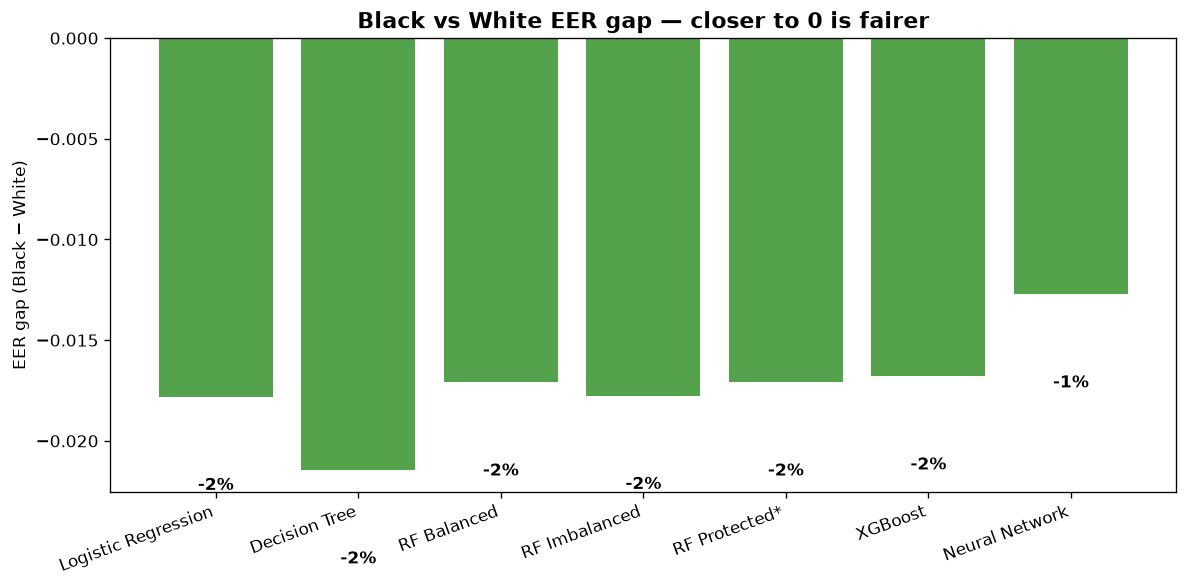

EER = threshold where false approvals ≈ false denials.
Lower overall EER = better ranking/separation.
EER gap near 0 = Black and White face a similar error tradeoff.


In [7]:
# Black-White EER gap
x = np.arange(len(eer_scorecard))
vals = eer_scorecard['eer_gap_bw'].to_numpy()
fig, ax = plt.subplots(figsize=(10, 5))
colors_bar = ['#E45756' if v > 0 else '#54A24B' for v in vals]
bars = ax.bar(x, vals, color=colors_bar)
ax.axhline(0, color='black', lw=1)
for bar, v in zip(bars, vals):
  ax.text(bar.get_x()+bar.get_width()/2, v+0.002 if v >= 0 else v-0.004, f'{v:+.0%}',
          ha='center', va='bottom' if v >= 0 else 'top', fontsize=10, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(eer_scorecard['model'], rotation=20, ha='right')
ax.set_ylabel('EER gap (Black − White)')
ax.set_title('Black vs White EER gap — closer to 0 is fairer', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print('EER = threshold where false approvals ≈ false denials.')
print('Lower overall EER = better ranking/separation.')
print('EER gap near 0 = Black and White face a similar error tradeoff.')
